# Skill 03 — Análisis cuantitativo (v2)

**Club de Finanzas e Inversiones · material educativo · no es asesoría de inversión**

1. **Archivo → Guardar una copia en Drive** para trabajar en tu propia versión.
2. Ejecuta la celda 1 (instala `yfinance` y `arch`).
3. En la celda 2, cambia `TICKER` y `BENCHMARK` y ejecútala (toma unos segundos).
4. Copia el resumen que se imprime al final y pégalo en tu chat con la skill 03.


In [1]:
# Celda 1 — instalar librerías: datos de Yahoo Finance y modelos GARCH
!pip install yfinance arch --quiet

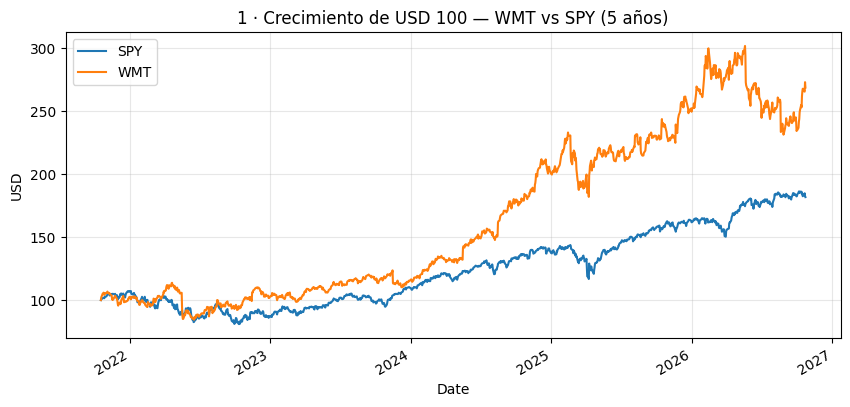

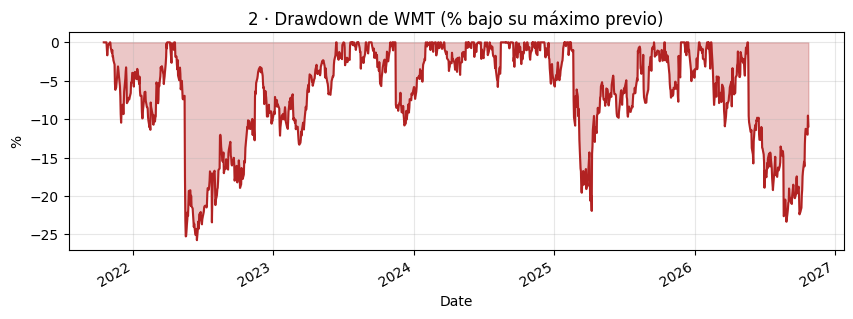

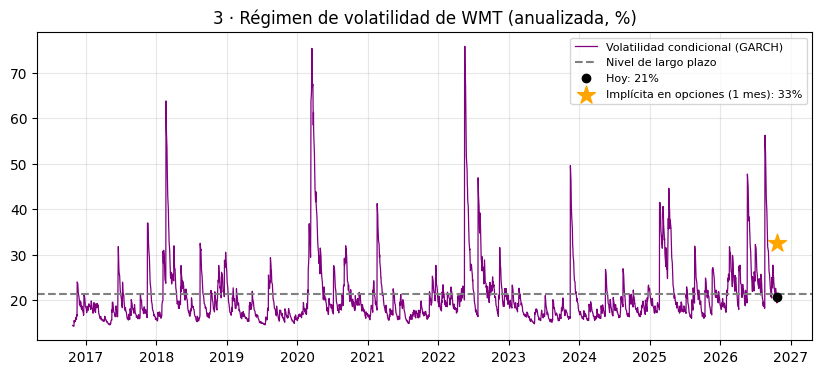

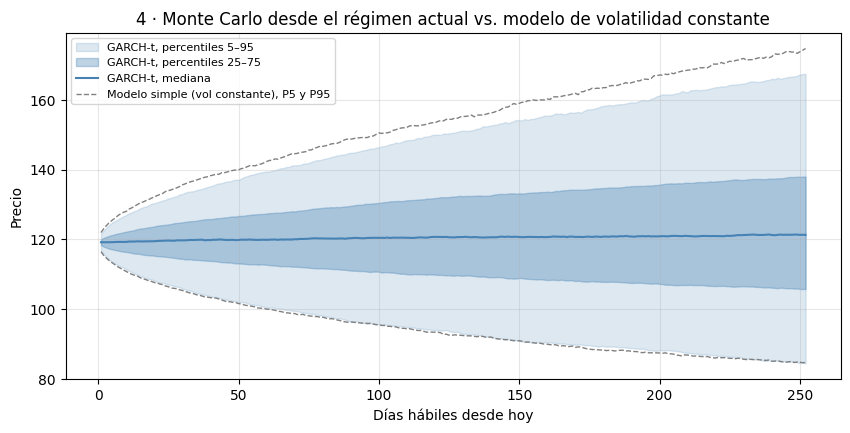

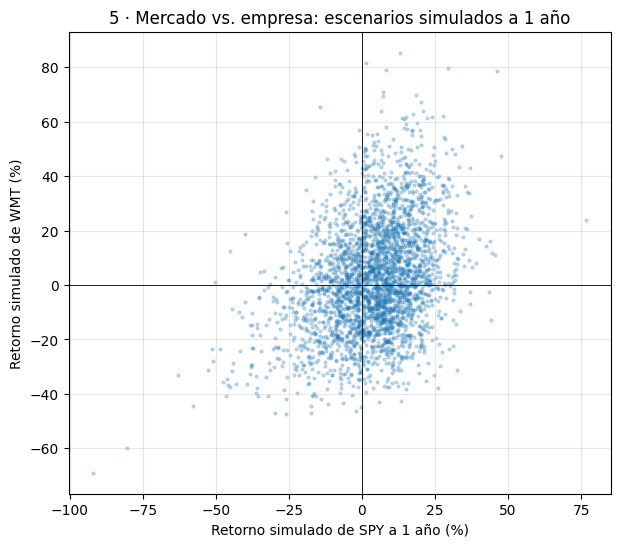

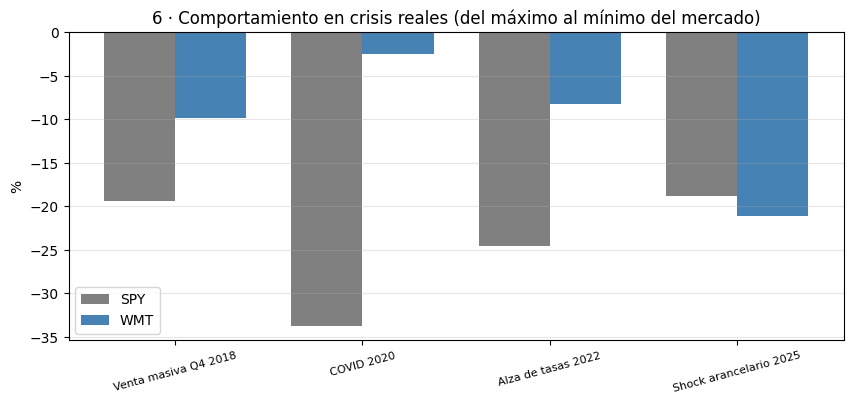

## RESULTADOS CUANTITATIVOS v2 — WMT vs SPY
Fuente: Yahoo Finance (precios ajustados) · Modelos calibrados con 2016-10-25 a 2026-10-23 · Semilla 42 · Deriva: libre_de_riesgo

### 1. Backtest (5 años)

| Métrica | WMT | SPY |
|---|---|---|
| CAGR | 21.9% | 12.7% |
| Volatilidad anual | 22.7% | 17.1% |
| Máx. drawdown | -25.7% | -24.5% |
| Sharpe | 0.81 | 0.55 |
| Sortino | 1.02 | 0.77 |

Máx. drawdown de WMT entre 2022-04-21 y 2022-06-17.

### 2. Régimen de volatilidad

- Volatilidad de hoy (GARCH): **21.8%** anualizada → percentil 75 de los últimos 10 años (0 = la más baja, 100 = la más alta).
- Nivel de largo plazo al que tiende: 21.4% · Persistencia: 0.940 (cercana a 1 = los shocks de volatilidad duran mucho).
- Asimetría: las caídas suben la volatilidad más que las alzas (gamma = 0.080). Colas: t-Student con 3.8 grados de libertad (menos = colas más gordas).
- Volatilidad implícita en opciones (28 días, venc. 2026-11-20): 32.7% vs. modelo 21.7% → el mercado de opciones espera MÁS ri

In [2]:
# Celda 2 — análisis completo (cambia TICKER y BENCHMARK abajo)
# -*- coding: utf-8 -*-
"""
Análisis cuantitativo avanzado de una acción — v2
Club de Finanzas e Inversiones · material educativo · no es asesoría de inversión.

Qué responde (solo cambias TICKER y BENCHMARK):
  1. Backtest de 5 años contra el benchmark.
  2. Régimen de volatilidad: ¿la volatilidad de HOY es alta o baja frente a su historia?
     (modelo GJR-GARCH con colas gordas, librería `arch`) y comparación con la
     volatilidad implícita en el mercado de opciones.
  3. Monte Carlo que parte del régimen actual, con riesgos de trayectoria
     (probabilidad de caer 20% en algún momento del año, no solo al final).
  4. Descomposición del riesgo: cuánto es mercado (beta) y cuánto es la empresa.
  5. Escenarios condicionales: ¿qué le pasa a la acción si el benchmark cae?
  6. Crisis reales: cómo se comportó en Q4-2018, COVID, 2022 y aranceles 2025.
  7. Validación del modelo: backtest del VaR diario sobre miles de días (test de Kupiec).

Cómo correrlo en Google Colab:
    Celda 1:  !pip install yfinance arch --quiet
    Celda 2:  este script. Cambia TICKER y BENCHMARK y ejecuta.

Determinista: con los mismos precios y la misma SEMILLA, los resultados son idénticos.
"""

import json
import sys
import warnings
from datetime import date

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

warnings.filterwarnings("ignore")

# ============================================================
# CONFIGURACIÓN — normalmente solo cambias las dos primeras líneas
# ============================================================
TICKER = "WMT"        # acción (ticker de Yahoo Finance)
BENCHMARK = "SPY"      # índice o ETF de comparación (SPY = S&P 500; XLK, XLF, XLE = sectores)
ANOS_MODELO = 10       # años para calibrar los modelos (más datos = mejor estimación de colas)
ANOS_BACKTEST = 5      # años para el backtest de rendimiento
HORIZONTE_DIAS = 252   # horizonte de la simulación (252 días hábiles ≈ 1 año)
N_SIMULACIONES = 10_000
SEMILLA = 42
TASA_LIBRE_RIESGO = 0.04  # anual. Actualizar con el T-bill a 3 meses (FRED: DTB3)
# Retorno promedio que asume la simulación (el supuesto más débil de cualquier Monte Carlo):
#   "libre_de_riesgo": no extrapola el pasado.  "historico": supone que se repite el retorno histórico.
DERIVA = "libre_de_riesgo"
MODO_DEMO = "--demo" in sys.argv  # datos sintéticos para probar el código sin internet

DIAS_ANO = 252

# Crisis de mercado con fechas de máximo a mínimo del S&P 500 (cierres)
CRISIS = [
    ("Crisis financiera 2008", "2007-10-09", "2009-03-09"),
    ("Venta masiva Q4 2018", "2018-09-20", "2018-12-24"),
    ("COVID 2020", "2020-02-19", "2020-03-23"),
    ("Alza de tasas 2022", "2022-01-03", "2022-10-12"),
    ("Shock arancelario 2025", "2025-02-19", "2025-04-08"),
]


# ============================================================
# 1. DATOS
# ============================================================
def descargar_precios():
    import yfinance as yf
    datos = yf.download([TICKER, BENCHMARK], period=f"{ANOS_MODELO}y", auto_adjust=True, progress=False)
    precios = datos["Close"].dropna()
    if precios.empty or len(precios) < 3 * DIAS_ANO:
        raise SystemExit(
            "Yahoo Finance no devolvió al menos 3 años de datos. Revisa el ticker, o corre el "
            "script en Google Colab (muchos entornos de chat no tienen internet)."
        )
    return precios


def precios_demo():
    """Serie sintética con volatilidad cambiante. NO es un dato real."""
    rng = np.random.default_rng(SEMILLA)
    n = ANOS_MODELO * DIAS_ANO
    fechas = pd.bdate_range(end=pd.Timestamp.today().normalize(), periods=n)
    s2, rm = 1e-4, np.zeros(n)
    for t in range(n):
        z = rng.standard_t(5) * np.sqrt(3 / 5)
        rm[t] = 0.0003 + np.sqrt(s2) * z
        s2 = 2e-6 + 0.08 * (rm[t] - 0.0003) ** 2 + 0.90 * s2
    rs = 0.0001 + 1.2 * rm + rng.standard_t(4, n) * 0.009
    return pd.DataFrame({TICKER: 100 * np.exp(np.cumsum(rs)), BENCHMARK: 400 * np.exp(np.cumsum(rm))}, index=fechas)


def volatilidad_implicita():
    """Volatilidad implícita at-the-money de las opciones listadas (si existen)."""
    if MODO_DEMO:
        return None
    try:
        import yfinance as yf
        t = yf.Ticker(TICKER)
        spot = float(t.history(period="5d")["Close"].iloc[-1])
        hoy = pd.Timestamp.today().normalize()
        venc = [(pd.Timestamp(v), v) for v in t.options]
        salida = {}
        for etiqueta, objetivo in (("1_mes", 30), ("1_ano", 365)):
            candidatos = [(abs((d - hoy).days - objetivo), d, v) for d, v in venc if (d - hoy).days > 7]
            if not candidatos:
                continue
            _, d, v = min(candidatos)
            cadena = t.option_chain(v)
            ivs = []
            for df in (cadena.calls, cadena.puts):
                df = df[(df["impliedVolatility"] > 0.01) & (df["impliedVolatility"] < 3)]
                if len(df):
                    fila = df.iloc[(df["strike"] - spot).abs().argsort()[:2]]
                    ivs.extend(fila["impliedVolatility"].tolist())
            if ivs:
                salida[etiqueta] = {"vencimiento": v, "dias": int((d - hoy).days), "iv": float(np.mean(ivs))}
        return salida or None
    except Exception:
        return None


# ============================================================
# 2. BACKTEST DE RENDIMIENTO
# ============================================================
def max_drawdown(serie):
    dd = serie / serie.cummax() - 1
    fondo = dd.idxmin()
    inicio = serie.loc[:fondo].idxmax()
    return dd, float(dd.min()), inicio, fondo


def metricas(precio, bench):
    r = np.log(precio / precio.shift(1)).dropna()
    rb = np.log(bench / bench.shift(1)).dropna()
    r, rb = r.align(rb, join="inner")
    simple = precio.pct_change().dropna()
    anos = len(r) / DIAS_ANO
    total = precio.iloc[-1] / precio.iloc[0] - 1
    rf_d = TASA_LIBRE_RIESGO / DIAS_ANO
    _, mdd, ini, fondo = max_drawdown(precio)
    return {
        "retorno_total": float(total),
        "cagr": float((1 + total) ** (1 / anos) - 1),
        "volatilidad_anual": float(r.std() * np.sqrt(DIAS_ANO)),
        "sharpe": float((simple.mean() - rf_d) / simple.std() * np.sqrt(DIAS_ANO)),
        "sortino": float((simple.mean() - rf_d) / simple[simple < 0].std() * np.sqrt(DIAS_ANO)),
        "max_drawdown": mdd,
        "max_drawdown_inicio": str(ini.date()),
        "max_drawdown_fondo": str(fondo.date()),
    }


# ============================================================
# 3. MODELO GJR-GARCH CON COLAS GORDAS (librería arch)
# ============================================================
def ajustar_garch(log_ret):
    """GJR-GARCH(1,1) con innovaciones t-Student. Captura tres hechos de los mercados:
    la volatilidad se agrupa, las caídas suben la volatilidad más que las alzas,
    y los días extremos son más frecuentes que en una normal."""
    from arch import arch_model
    y = log_ret * 100  # en porcentaje, para estabilidad numérica
    res = arch_model(y, mean="Constant", vol="GARCH", p=1, o=1, q=1, dist="t").fit(disp="off")
    p = res.params
    omega, alpha, gamma, beta, nu = p["omega"], p["alpha[1]"], p["gamma[1]"], p["beta[1]"], p["nu"]
    persistencia = alpha + 0.5 * gamma + beta
    s2_largo = omega / (1 - persistencia) if persistencia < 1 else float(np.var(y))
    e_ult = float(res.resid.iloc[-1])
    s2_ult = float(res.conditional_volatility.iloc[-1]) ** 2
    s2_sig = omega + (alpha + gamma * (e_ult < 0)) * e_ult ** 2 + beta * s2_ult
    return {
        "omega": omega, "alpha": alpha, "gamma": gamma, "beta": beta, "nu": nu, "mu_pct": p["mu"],
        "persistencia": persistencia,
        "vol_largo_plazo_anual": float(np.sqrt(s2_largo * DIAS_ANO) / 100),
        "s2_siguiente": s2_sig,
        "vol_condicional_hist": res.conditional_volatility / 100 * np.sqrt(DIAS_ANO),  # serie anualizada
        "resid_estandarizados": (res.resid / res.conditional_volatility).dropna(),
    }


def deriva_diaria(log_ret, vol_anual):
    if DERIVA == "historico":
        return float(log_ret.mean())
    return float(np.log(1 + TASA_LIBRE_RIESGO) / DIAS_ANO - 0.5 * (vol_anual ** 2) / DIAS_ANO)


def simular_garch(g, mu_d, n, h, rng):
    """Simula retornos diarios en logaritmos partiendo de la volatilidad de hoy."""
    nu = g["nu"]
    z = rng.standard_t(nu, size=(n, h)) * np.sqrt((nu - 2) / nu)
    s2 = np.full(n, g["s2_siguiente"])
    ret = np.empty((n, h))
    for t in range(h):
        e = np.sqrt(s2) * z[:, t]
        ret[:, t] = mu_d + e / 100
        s2 = g["omega"] + (g["alpha"] + g["gamma"] * (e < 0)) * e ** 2 + g["beta"] * s2
    return ret


def simular_gbm(mu_d, sigma_d, n, h, rng):
    return mu_d + sigma_d * rng.standard_normal((n, h))


def resumen(ret_diarios, p0):
    caminos = p0 * np.exp(np.cumsum(ret_diarios, axis=1))
    final = caminos[:, -1]
    r = final / p0 - 1
    minimo = caminos.min(axis=1) / p0 - 1
    maximo = caminos.max(axis=1) / p0 - 1
    dd_camino = (caminos / np.maximum.accumulate(caminos, axis=1) - 1).min(axis=1)
    var95 = np.percentile(r, 5)
    return caminos, {
        "p5": float(np.percentile(final, 5)), "p25": float(np.percentile(final, 25)),
        "mediana": float(np.median(final)), "p75": float(np.percentile(final, 75)),
        "p95": float(np.percentile(final, 95)),
        "prob_perdida_al_final": float((r < 0).mean()),
        "var_95": float(var95), "cvar_95": float(r[r <= var95].mean()),
        "prob_caer_20pct_en_algun_momento": float((minimo <= -0.20).mean()),
        "prob_subir_20pct_en_algun_momento": float((maximo >= 0.20).mean()),
        "drawdown_mediano_en_el_ano": float(np.median(dd_camino)),
    }


# ============================================================
# 4. MERCADO vs EMPRESA (modelo de un factor)
# ============================================================
def modelo_factor(r, rb):
    X = np.column_stack([np.ones(len(rb)), rb.values])
    coef, *_ = np.linalg.lstsq(X, r.values, rcond=None)
    alfa, beta = coef
    resid = r.values - X @ coef
    r2 = 1 - resid.var() / r.values.var()
    return {"beta": float(beta), "alfa_diario": float(alfa), "r2": float(r2),
            "vol_idiosincratica_anual": float(resid.std() * np.sqrt(DIAS_ANO)), "resid": resid}


def simular_conjunto(fac, g_bench, mu_bench, mu_accion, n, h, rng, bloque=21):
    """Simula el benchmark con su propio GARCH y la acción como beta × mercado + componente propio.
    El componente propio se re-muestrea en bloques de la historia real (conserva sus colas)."""
    m = simular_garch(g_bench, mu_bench, n, h, rng)
    e = fac["resid"] - fac["resid"].mean()
    n_bloques = int(np.ceil(h / bloque))
    inicios = rng.integers(0, len(e) - bloque, size=(n, n_bloques))
    idx = (inicios[:, :, None] + np.arange(bloque)).reshape(n, -1)[:, :h]
    s = mu_accion + fac["beta"] * (m - mu_bench) + e[idx]
    return np.expm1(m.sum(axis=1)), np.expm1(s.sum(axis=1))


def tabla_condicional(ret_m, ret_s):
    tramos = [("Benchmark cae más de 15%", -np.inf, -0.15), ("Benchmark cae 0–15%", -0.15, 0.0),
              ("Benchmark sube 0–15%", 0.0, 0.15), ("Benchmark sube más de 15%", 0.15, np.inf)]
    filas = []
    for nombre, lo, hi in tramos:
        sel = (ret_m > lo) & (ret_m <= hi)
        if sel.sum() < 50:
            filas.append({"escenario": nombre, "frecuencia": float(sel.mean()), "mediana": None, "p5": None, "p95": None})
            continue
        x = ret_s[sel]
        filas.append({"escenario": nombre, "frecuencia": float(sel.mean()), "mediana": float(np.median(x)),
                      "p5": float(np.percentile(x, 5)), "p95": float(np.percentile(x, 95))})
    return filas


# ============================================================
# 5. CRISIS REALES
# ============================================================
def crisis_historicas(precios, beta):
    filas = []
    for nombre, ini, fin in CRISIS:
        ini, fin = pd.Timestamp(ini), pd.Timestamp(fin)
        tramo = precios.loc[ini - pd.Timedelta(days=4): fin + pd.Timedelta(days=4)]
        if precios.index[0] > ini or len(tramo) < 5:
            continue
        a = tramo.loc[:ini].iloc[-1] if len(tramo.loc[:ini]) else tramo.iloc[0]
        b = tramo.loc[:fin].iloc[-1]
        rb = float(b[BENCHMARK] / a[BENCHMARK] - 1)
        rs = float(b[TICKER] / a[TICKER] - 1)
        filas.append({"crisis": nombre, "desde": str(ini.date()), "hasta": str(fin.date()),
                      "benchmark": rb, "accion": rs, "implicito_por_beta": float(beta * rb)})
    return filas


# ============================================================
# 6. VALIDACIÓN: BACKTEST DEL VaR DIARIO (test de Kupiec)
# ============================================================
def backtest_var(log_ret, g, nivel=0.95):
    """¿Cuántos días la pérdida superó el VaR que el modelo calculaba para ese día?
    Si el modelo está bien calibrado, debería pasar en ~5% de los días."""
    vol_d = g["vol_condicional_hist"] / np.sqrt(DIAS_ANO)
    nu = g["nu"]
    q = stats.t.ppf(1 - nivel, nu) * np.sqrt((nu - 2) / nu)
    umbral = g["mu_pct"] / 100 + vol_d * q
    r, u = log_ret.align(umbral, join="inner")
    excepciones = (r < u).astype(int)
    n, x = len(excepciones), int(excepciones.sum())
    p_hat = x / n
    p = 1 - nivel
    if 0 < x < n:
        lr = -2 * ((n - x) * np.log(1 - p) + x * np.log(p) - (n - x) * np.log(1 - p_hat) - x * np.log(p_hat))
        p_valor = float(1 - stats.chi2.cdf(lr, 1))
    else:
        p_valor = 0.0
    sigma_const = log_ret.std()
    q_normal = stats.norm.ppf(1 - nivel)
    exc_const = float((log_ret < log_ret.mean() + sigma_const * q_normal).mean())
    return {"dias": n, "excepciones": x, "tasa": p_hat, "esperada": p, "p_valor_kupiec": p_valor,
            "tasa_modelo_vol_constante": exc_const}


# ============================================================
# 7. GRÁFICOS
# ============================================================
def graficar(prec_bt, dd, g, iv, cam_garch, cam_gbm, ret_m, ret_s, crisis, prefijo):
    archivos = []

    def guardar(fig, nombre):
        f = f"{prefijo}_{nombre}.png"
        fig.savefig(f, dpi=130, bbox_inches="tight")
        archivos.append(f)

    fig, ax = plt.subplots(figsize=(10, 4.5))
    (100 * prec_bt / prec_bt.iloc[0]).plot(ax=ax)
    ax.set_title(f"1 · Crecimiento de USD 100 — {TICKER} vs {BENCHMARK} ({ANOS_BACKTEST} años)")
    ax.set_ylabel("USD"); ax.grid(alpha=0.3)
    guardar(fig, "1_crecimiento")

    fig, ax = plt.subplots(figsize=(10, 3.2))
    (dd * 100).plot(ax=ax, color="firebrick")
    ax.fill_between(dd.index, dd * 100, 0, color="firebrick", alpha=0.25)
    ax.set_title(f"2 · Drawdown de {TICKER} (% bajo su máximo previo)"); ax.set_ylabel("%"); ax.grid(alpha=0.3)
    guardar(fig, "2_drawdown")

    fig, ax = plt.subplots(figsize=(10, 4))
    vc = g["vol_condicional_hist"] * 100
    ax.plot(vc.index, vc.values, color="purple", lw=0.9, label="Volatilidad condicional (GARCH)")
    ax.axhline(g["vol_largo_plazo_anual"] * 100, color="gray", ls="--", label="Nivel de largo plazo")
    ax.scatter([vc.index[-1]], [vc.iloc[-1]], color="black", zorder=5, label=f"Hoy: {vc.iloc[-1]:.0f}%")
    if iv and "1_mes" in iv:
        ax.scatter([vc.index[-1]], [iv["1_mes"]["iv"] * 100], marker="*", s=180, color="orange", zorder=6,
                   label=f"Implícita en opciones (1 mes): {iv['1_mes']['iv'] * 100:.0f}%")
    ax.set_title(f"3 · Régimen de volatilidad de {TICKER} (anualizada, %)"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
    guardar(fig, "3_regimen_volatilidad")

    fig, ax = plt.subplots(figsize=(10, 4.5))
    dias = np.arange(1, HORIZONTE_DIAS + 1)
    for lo, hi, a in ((5, 95, 0.18), (25, 75, 0.35)):
        ax.fill_between(dias, np.percentile(cam_garch, lo, axis=0), np.percentile(cam_garch, hi, axis=0),
                        color="steelblue", alpha=a, label=f"GARCH-t, percentiles {lo}–{hi}")
    ax.plot(dias, np.median(cam_garch, axis=0), color="steelblue", lw=1.5, label="GARCH-t, mediana")
    for q in (5, 95):
        ax.plot(dias, np.percentile(cam_gbm, q, axis=0), color="gray", ls="--", lw=1,
                label="Modelo simple (vol constante), P5 y P95" if q == 5 else None)
    ax.set_xlabel("Días hábiles desde hoy"); ax.set_ylabel("Precio")
    ax.set_title("4 · Monte Carlo desde el régimen actual vs. modelo de volatilidad constante")
    ax.grid(alpha=0.3); ax.legend(fontsize=8, loc="upper left")
    guardar(fig, "4_montecarlo")

    fig, ax = plt.subplots(figsize=(7, 6))
    k = min(3000, len(ret_m))
    ax.scatter(ret_m[:k] * 100, ret_s[:k] * 100, s=4, alpha=0.25)
    ax.axhline(0, color="black", lw=0.6); ax.axvline(0, color="black", lw=0.6)
    ax.set_xlabel(f"Retorno simulado de {BENCHMARK} a 1 año (%)"); ax.set_ylabel(f"Retorno simulado de {TICKER} (%)")
    ax.set_title("5 · Mercado vs. empresa: escenarios simulados a 1 año"); ax.grid(alpha=0.3)
    guardar(fig, "5_escenarios_condicionales")

    if crisis:
        fig, ax = plt.subplots(figsize=(10, 4))
        x = np.arange(len(crisis)); w = 0.38
        ax.bar(x - w / 2, [c["benchmark"] * 100 for c in crisis], w, label=BENCHMARK, color="gray")
        ax.bar(x + w / 2, [c["accion"] * 100 for c in crisis], w, label=TICKER, color="steelblue")
        ax.set_xticks(x); ax.set_xticklabels([c["crisis"] for c in crisis], rotation=15, fontsize=8)
        ax.axhline(0, color="black", lw=0.6); ax.set_ylabel("%"); ax.legend(); ax.grid(alpha=0.3, axis="y")
        ax.set_title("6 · Comportamiento en crisis reales (del máximo al mínimo del mercado)")
        guardar(fig, "6_crisis")

    if "ipykernel" in sys.modules:
        plt.show()
    plt.close("all")
    return archivos


# ============================================================
# 8. EJECUCIÓN
# ============================================================
def pct(x, d=1):
    return "n/d" if x is None else f"{x * 100:,.{d}f}%"


def main():
    if MODO_DEMO:
        print("⚠️  MODO DEMO: datos sintéticos. Ningún número de esta corrida es real.\n")
    precios = precios_demo() if MODO_DEMO else descargar_precios()
    precios.columns = [str(c) for c in precios.columns]
    prefijo = f"{TICKER}_{date.today().isoformat()}" + ("_DEMO" if MODO_DEMO else "")
    precios.to_csv(f"{prefijo}_precios.csv")

    p, pb = precios[TICKER], precios[BENCHMARK]
    r = np.log(p / p.shift(1)).dropna()
    rb = np.log(pb / pb.shift(1)).dropna()
    r, rb = r.align(rb, join="inner")
    p0 = float(p.iloc[-1])
    rngs = [np.random.default_rng(s) for s in np.random.SeedSequence(SEMILLA).spawn(3)]

    # Backtest de rendimiento
    prec_bt = precios.iloc[-ANOS_BACKTEST * DIAS_ANO:]
    bt = {TICKER: metricas(prec_bt[TICKER], prec_bt[BENCHMARK]),
          BENCHMARK: metricas(prec_bt[BENCHMARK], prec_bt[BENCHMARK])}
    dd, *_ = max_drawdown(prec_bt[TICKER])

    # Régimen de volatilidad
    g = ajustar_garch(r)
    vc = g["vol_condicional_hist"]
    vol_hoy = float(np.sqrt(g["s2_siguiente"] * DIAS_ANO) / 100)
    percentil_hoy = float((vc < vol_hoy).mean() * 100)
    vol_hist = float(r.std() * np.sqrt(DIAS_ANO))
    iv = volatilidad_implicita()

    # Monte Carlo
    mu_s = deriva_diaria(r, vol_hist)
    cam_garch, mc_garch = resumen(simular_garch(g, mu_s, N_SIMULACIONES, HORIZONTE_DIAS, rngs[0]), p0)
    cam_gbm, mc_gbm = resumen(simular_gbm(mu_s, r.std(), N_SIMULACIONES, HORIZONTE_DIAS, rngs[1]), p0)
    vol_garch_1m = float(np.sqrt(np.diff(np.log(cam_garch[:, :22]), axis=1).var(axis=0).mean() * DIAS_ANO))
    vol_garch_1a = float(np.log(cam_garch[:, -1] / p0).std() / np.sqrt(HORIZONTE_DIAS / DIAS_ANO))

    # Mercado vs empresa
    fac = modelo_factor(r, rb)
    g_b = ajustar_garch(rb)
    mu_b = deriva_diaria(rb, float(rb.std() * np.sqrt(DIAS_ANO)))
    ret_m, ret_s = simular_conjunto(fac, g_b, mu_b, mu_s, N_SIMULACIONES, HORIZONTE_DIAS, rngs[2])
    cond = tabla_condicional(ret_m, ret_s)

    # Crisis y validación
    crisis = crisis_historicas(precios, fac["beta"])
    vb = backtest_var(r, g)

    graficos = graficar(prec_bt, dd, g, iv, cam_garch, cam_gbm, ret_m, ret_s, crisis, prefijo)

    resultado = {
        "ticker": TICKER, "benchmark": BENCHMARK, "modo_demo": MODO_DEMO, "fecha_corrida": date.today().isoformat(),
        "datos_modelo": [str(r.index[0].date()), str(r.index[-1].date())],
        "parametros": {"anos_modelo": ANOS_MODELO, "anos_backtest": ANOS_BACKTEST, "horizonte_dias": HORIZONTE_DIAS,
                       "simulaciones": N_SIMULACIONES, "semilla": SEMILLA, "deriva": DERIVA,
                       "tasa_libre_riesgo": TASA_LIBRE_RIESGO},
        "backtest": bt,
        "regimen": {"vol_hoy": vol_hoy, "percentil_hoy": percentil_hoy, "vol_largo_plazo": g["vol_largo_plazo_anual"],
                    "vol_historica_simple": vol_hist, "persistencia": g["persistencia"], "asimetria_gamma": g["gamma"],
                    "grados_libertad_t": g["nu"], "vol_modelo_1m": vol_garch_1m, "vol_modelo_1a": vol_garch_1a,
                    "vol_implicita": iv},
        "montecarlo": {"garch_t": mc_garch, "volatilidad_constante": mc_gbm},
        "factor": {k: v for k, v in fac.items() if k != "resid"},
        "condicional": cond, "crisis": crisis, "validacion_var": vb, "graficos": graficos,
    }
    with open(f"{prefijo}_resultados.json", "w", encoding="utf-8") as fh:
        json.dump(resultado, fh, ensure_ascii=False, indent=2, default=float)

    # ---------------- Resumen para pegar en el chat ----------------
    A, B = bt[TICKER], bt[BENCHMARK]
    print(f"## RESULTADOS CUANTITATIVOS v2 — {TICKER} vs {BENCHMARK}" + ("  ⚠️ DEMO, NO REAL" if MODO_DEMO else ""))
    print(f"Fuente: Yahoo Finance (precios ajustados) · Modelos calibrados con {resultado['datos_modelo'][0]} a "
          f"{resultado['datos_modelo'][1]} · Semilla {SEMILLA} · Deriva: {DERIVA}\n")

    print(f"### 1. Backtest ({ANOS_BACKTEST} años)\n")
    print(f"| Métrica | {TICKER} | {BENCHMARK} |\n|---|---|---|")
    for et, k in (("CAGR", "cagr"), ("Volatilidad anual", "volatilidad_anual"), ("Máx. drawdown", "max_drawdown")):
        print(f"| {et} | {pct(A[k])} | {pct(B[k])} |")
    print(f"| Sharpe | {A['sharpe']:.2f} | {B['sharpe']:.2f} |\n| Sortino | {A['sortino']:.2f} | {B['sortino']:.2f} |")
    print(f"\nMáx. drawdown de {TICKER} entre {A['max_drawdown_inicio']} y {A['max_drawdown_fondo']}.\n")

    print("### 2. Régimen de volatilidad\n")
    print(f"- Volatilidad de hoy (GARCH): **{pct(vol_hoy)}** anualizada → percentil {percentil_hoy:.0f} de los últimos "
          f"{ANOS_MODELO} años (0 = la más baja, 100 = la más alta).")
    print(f"- Nivel de largo plazo al que tiende: {pct(g['vol_largo_plazo_anual'])} · Persistencia: {g['persistencia']:.3f} "
          f"(cercana a 1 = los shocks de volatilidad duran mucho).")
    print(f"- Asimetría: las caídas suben la volatilidad {'más' if g['gamma'] > 0 else 'menos'} que las alzas "
          f"(gamma = {g['gamma']:.3f}). Colas: t-Student con {g['nu']:.1f} grados de libertad (menos = colas más gordas).")
    if iv:
        for et, v in iv.items():
            ref = vol_garch_1m if et == "1_mes" else vol_garch_1a
            print(f"- Volatilidad implícita en opciones ({v['dias']} días, venc. {v['vencimiento']}): {pct(v['iv'])} "
                  f"vs. modelo {pct(ref)} → el mercado de opciones espera {'MÁS' if v['iv'] > ref else 'MENOS'} riesgo que el modelo histórico.")
    else:
        print("- Volatilidad implícita en opciones: no disponible.")

    print(f"\n### 3. Monte Carlo a {HORIZONTE_DIAS} días hábiles · precio inicial {p0:,.2f}\n")
    print("| Modelo | P5 | Mediana | P95 | VaR 95% | CVaR 95% | Prob. caer 20% en algún momento | Prob. subir 20% en algún momento | Drawdown mediano en el año |")
    print("|---|---|---|---|---|---|---|---|---|")
    for et, m in (("GARCH-t (régimen actual)", mc_garch), ("Volatilidad constante", mc_gbm)):
        print(f"| {et} | {m['p5']:,.2f} | {m['mediana']:,.2f} | {m['p95']:,.2f} | {pct(m['var_95'])} | {pct(m['cvar_95'])} | "
              f"{pct(m['prob_caer_20pct_en_algun_momento'])} | {pct(m['prob_subir_20pct_en_algun_momento'])} | "
              f"{pct(m['drawdown_mediano_en_el_ano'])} |")

    print("\n### 4. Mercado vs. empresa\n")
    print(f"- Beta: {fac['beta']:.2f} · El mercado explica el {pct(fac['r2'], 0)} de la variación diaria; "
          f"el {pct(1 - fac['r2'], 0)} restante es propio de la empresa (vol. idiosincrática {pct(fac['vol_idiosincratica_anual'])}).\n")
    print(f"| Escenario a 1 año | Frecuencia simulada | Mediana de {TICKER} | P5 | P95 |\n|---|---|---|---|---|")
    for c in cond:
        print(f"| {c['escenario']} | {pct(c['frecuencia'], 0)} | {pct(c['mediana'])} | {pct(c['p5'])} | {pct(c['p95'])} |")

    print("\n### 5. Crisis reales (del máximo al mínimo del S&P 500)\n")
    if crisis:
        print(f"| Crisis | {BENCHMARK} | {TICKER} real | {TICKER} según su beta |\n|---|---|---|---|")
        for c in crisis:
            print(f"| {c['crisis']} ({c['desde']} a {c['hasta']}) | {pct(c['benchmark'])} | {pct(c['accion'])} | {pct(c['implicito_por_beta'])} |")
    else:
        print("Sin crisis dentro del período de datos.")

    print("\n### 6. Validación del modelo (VaR diario 95%)\n")
    print(f"- En {vb['dias']:,} días, la pérdida superó el VaR del modelo GARCH-t en {pct(vb['tasa'])} de los días "
          f"(lo esperado es 5,0%). Test de Kupiec: p = {vb['p_valor_kupiec']:.2f} "
          f"({'no se rechaza: calibración aceptable' if vb['p_valor_kupiec'] > 0.05 else 'se rechaza: el modelo está mal calibrado'}).")
    print(f"- Un modelo de volatilidad constante con distribución normal falla en {pct(vb['tasa_modelo_vol_constante'])} de los días.")
    print("- Nota: los parámetros se estiman con toda la muestra, así que es una validación dentro de muestra.\n")

    print(f"Archivos: {', '.join(graficos)}, {prefijo}_resultados.json, {prefijo}_precios.csv")
    print("\nNinguna simulación predice la dirección del precio. Cuantifica riesgo bajo supuestos explícitos. No es una recomendación.")


if __name__ == "__main__":
    main()